In [7]:
!unzip -q /content/nfl-inference.zip -d /content/Computer-Vision-NFL
%cd /content/Computer-Vision-NFL

/content/Computer-Vision-NFL


In [8]:
%pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 74.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 MB 76.9 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 182.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 110.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 165.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 950.3/950.3 kB 53.4 MB/s  0:00:00
  Attempting uninstall: widgetsnbextension
    Found existing installation: widgetsnbextension 3.6.10
    Uninstalling widgetsnbextension-3.6.10:
      Successfully uninstalled widgetsnbextension-3.6.10
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 5.0.0.93
    Uninstalling opencv-python-5.0.0.93:
      Successfully uninstalled opencv-python-5.0.0.93
  Attempting uninstall: jupyter-client
    Found existing installation: jupyter_client 7.4.9
    Uninstalling jupyter_client-7.4.9:
      Successfully un

In [9]:
!python -u -m src.impact.inference \
  --video /content/NFL_Test.mp4 \
  --output /content/NFL_test_results \
  --device auto

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/content/Computer-Vision-NFL/artifacts/ultralytics/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Detect and score: 100% 269/269 [01:46<00:00,  2.53frame/s]
Render MP4: 100% 269/269 [00:04<00:00, 61.55frame/s]
{
  "video": "/content/NFL_Test.mp4",
  "classifier": "/content/Computer-Vision-NFL/weights/impact_best.pt",
  "helmet": "/content/Computer-Vision-NFL/weights/helmet_best.pt",
  "device": "cuda",
  "fps": 30.0,
  "frames": 269,
  "threshold": 0.1153564453125,
  "batch_size": 8,
  "detector_confidence": 0.15,
  "track_iou": 0.1,
  "track_max_missing": 4,
  "event_gap": 4,
  "tracks": 342,
  "candidates": 5828,
  "events": 390,
  "annotated_video": "annotated.mp4",
  "position_source": "YOLO detections linked by video-local helmet tracks"
}


In [10]:
import json
import subprocess
from pathlib import Path

import pandas as pd
from IPython.display import Video, display

results = Path("/content/NFL_test_results")
summary = json.loads((results / "summary.json").read_text())
impacts = pd.read_csv(results / "impacts.csv")

print(f"{summary['frames']} frames • {summary['tracks']} helmet tracks • "
      f"{summary['candidates']} scored candidates • {summary['events']} flagged impacts")

if impacts.empty:
    print(f"No impacts reached the score threshold of {summary['threshold']:.3f}.")
else:
    display(impacts[[
        "event_id", "track_id", "start_seconds", "peak_seconds",
        "end_seconds", "probability"
    ]].round(3))

# Convert the annotated MP4 to H.264 for playback in the notebook.
playback = results / "notebook_playback.mp4"
subprocess.run([
    "ffmpeg", "-y", "-loglevel", "error",
    "-i", str(results / "annotated.mp4"),
    "-c:v", "libx264", "-pix_fmt", "yuv420p",
    "-movflags", "+faststart", str(playback)
], check=True)
display(Video(str(playback), embed=True, width=900))

269 frames • 342 helmet tracks • 5828 scored candidates • 390 flagged impacts


,event_id,track_id,start_seconds,peak_seconds,end_seconds,probability
0,1,8,0.667,0.700,0.700,0.600
1,2,25,1.500,1.633,1.633,0.259
2,3,19,1.667,1.667,1.667,0.206
3,4,9,1.733,1.767,1.767,0.137
4,5,20,1.733,1.800,1.800,0.558
...,...,...,...,...,...,...
385,386,331,8.800,8.800,8.800,0.197
386,387,327,8.833,8.867,8.867,0.188
387,388,339,8.867,8.867,8.867,0.477
388,389,340,8.867,8.933,8.933,0.859


## Impact-only review

Run this after inference or reopen the session with `NFL_Test.mp4` and `/content/NFL_test_results` available. This cell reuses the saved candidate scores and renders a separate video from the original clip. The review starts at an impact score of 0.70, requires three qualifying frames per track event, and shows up to ten events. Adjust those settings and rerun this cell to compare. These are review settings for this clip.

The shaded score graphic produced false boxes in the original video. The ignore region below uses normalized image coordinates `(left, top, right, bottom)` for the score graphic in this clip. Set `ignore_regions = ()` for clips without that overlay.

In [ ]:
import json
import subprocess
from pathlib import Path

import cv2
import pandas as pd
from IPython.display import Video, display
from src.impact.inference import group_events, render_events

video = Path("/content/NFL_Test.mp4")
results = Path("/content/NFL_test_results")
preview_threshold = 0.70
min_positive_frames = 3
max_preview_events = 10  # Set to None to show every event that passes the filters.
ignore_regions = ((0.29, 0.85, 0.83, 1.0),)  # Broadcast score graphic in this clip.

summary = json.loads((results / "summary.json").read_text())
candidates = pd.read_csv(results / "candidates.csv")
cap = cv2.VideoCapture(str(video))
try:
    if not cap.isOpened():
        raise FileNotFoundError(f"Could not open {video}")
    width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)
    height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
finally:
    cap.release()

center_x = (candidates.left + candidates.width / 2) / width
center_y = (candidates.top + candidates.height / 2) / height
masked = pd.Series(False, index=candidates.index)
for left, top, right, bottom in ignore_regions:
    masked |= center_x.between(left, right) & center_y.between(top, bottom)

visible = candidates.loc[~masked]
events = group_events(visible, preview_threshold, summary["event_gap"], summary["fps"])
eligible = events.loc[events.positive_frames.ge(min_positive_frames)]
selected = eligible.sort_values("probability", ascending=False)
if max_preview_events is not None:
    selected = selected.head(max_preview_events)
selected = selected.reset_index(drop=True)

print(f"Original run had {summary['events']} alerts at {summary['threshold']:.3f}.")
print(f"Review shows {len(selected)} of {len(eligible)} alerts that pass the filters. "
      f"Ignored {int(masked.sum())} helmet candidates in the score graphic region.")
if selected.empty:
    print("No alerts pass the review settings. Lower the score or frame requirement to review more.")

# Keep only observations belonging to a selected event's track and time span.
windows = selected[["track_id", "start_frame", "end_frame"]]
review_boxes = visible.merge(windows, on="track_id")
review_boxes = review_boxes.loc[
    review_boxes.frame.between(review_boxes.start_frame, review_boxes.end_frame)
]
display(selected[["track_id", "start_seconds", "peak_seconds", "end_seconds",
                  "probability", "positive_frames"]].round(3))

review_video = results / "impact_review.mp4"
playback = results / "impact_review_playback.mp4"
render_events(video, selected, review_video, predictions=review_boxes,
              frames=summary["frames"], progress=True)
subprocess.run([
    "ffmpeg", "-y", "-loglevel", "error", "-i", str(review_video),
    "-c:v", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", str(playback)
], check=True)
display(Video(str(playback), embed=True, width=900))

In [19]:
candidates = pd.read_csv(results / "candidates.csv")
display(candidates.nlargest(10, "probability"))

,video,frame,player,view,left,top,width,height,probability,missing_positions,track_id,detector_confidence
1750,NFL_Test.mp4,78,unknown,Test,629.671997,235.364548,17.855042,19.082687,0.998533,2,15,0.304719
1754,NFL_Test.mp4,78,unknown,Test,621.311096,229.343536,19.758850,22.158951,0.997456,4,32,0.232524
1755,NFL_Test.mp4,78,unknown,Test,632.867126,202.764969,20.201111,19.068512,0.992960,6,43,0.230817
2060,NFL_Test.mp4,92,unknown,Test,623.363403,198.075943,17.798340,19.103485,0.991849,2,56,0.565437
3862,NFL_Test.mp4,169,unknown,Test,516.649719,310.061249,26.186890,23.092651,0.989873,2,243,0.337889
2086,NFL_Test.mp4,93,unknown,Test,623.358398,198.065964,17.805847,19.115082,0.989772,3,56,0.565297
1752,NFL_Test.mp4,78,unknown,Test,646.025391,254.510452,18.955139,19.417892,0.985192,6,38,0.297271
1753,NFL_Test.mp4,78,unknown,Test,638.986511,209.511505,19.033081,15.188324,0.984765,4,36,0.257945
5281,NFL_Test.mp4,240,unknown,Test,835.937988,177.177124,28.631653,28.532394,0.984758,2,325,0.647875
1571,NFL_Test.mp4,71,unknown,Test,739.367920,371.306549,20.395691,19.093170,0.984065,0,11,0.727888


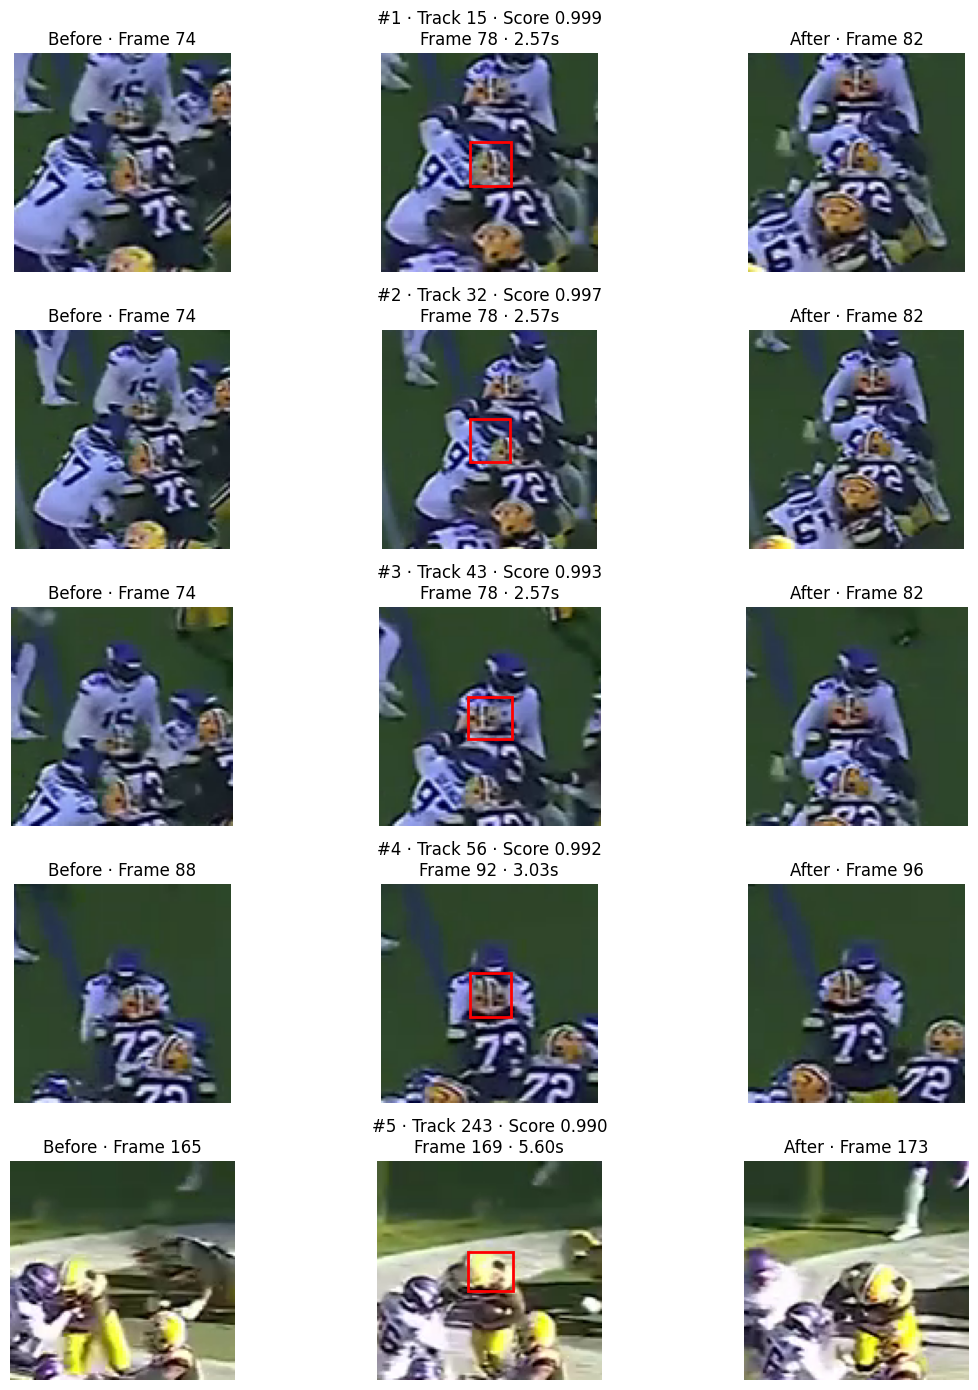

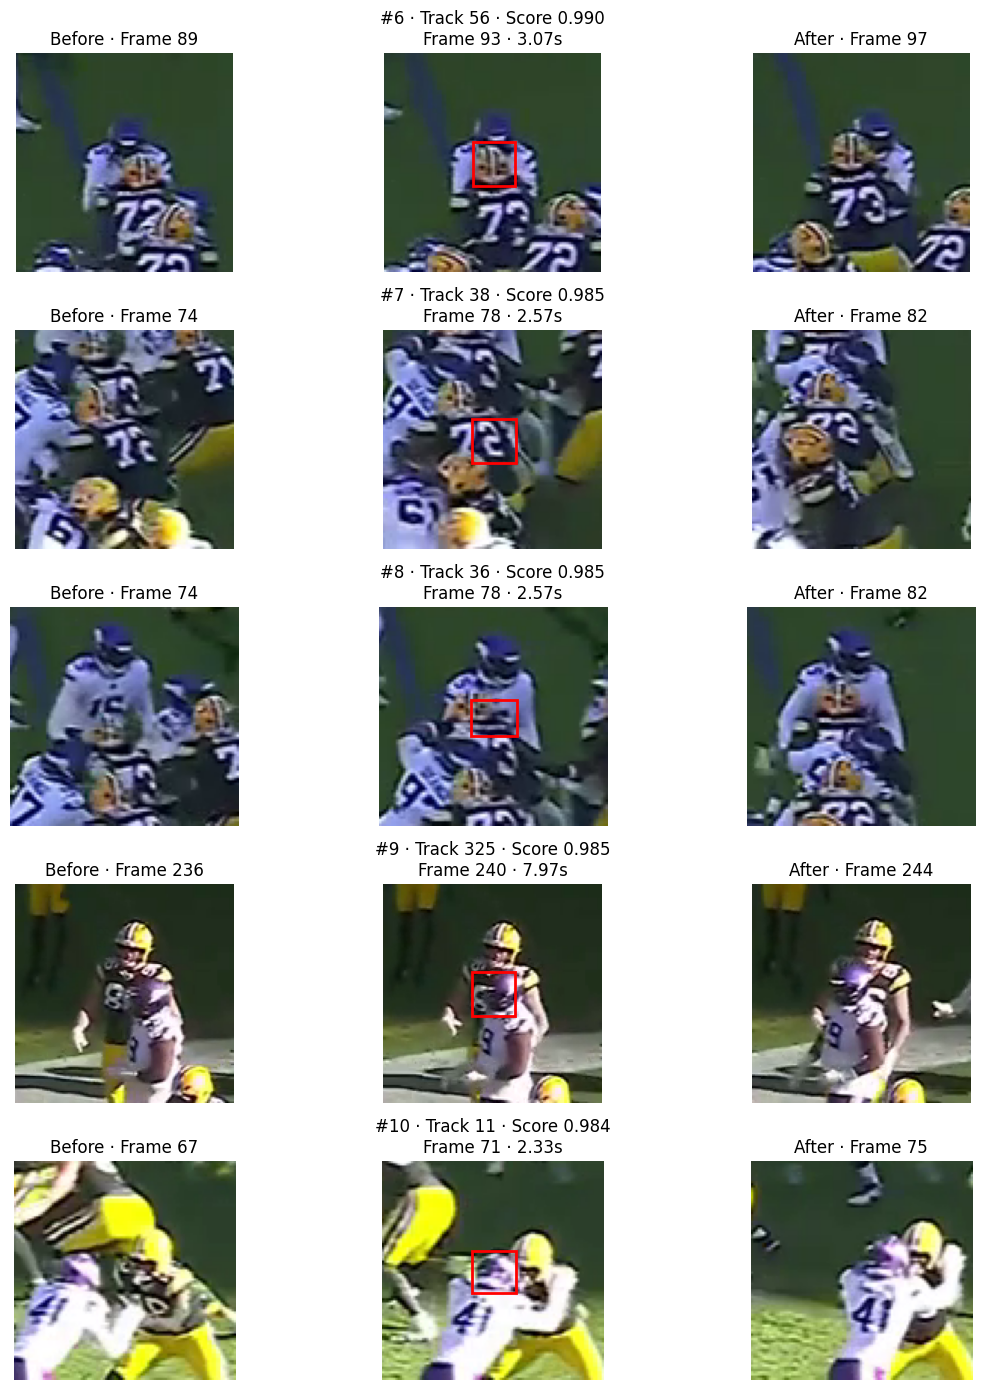

In [20]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import pandas as pd

results = Path("/content/NFL_test_results")
top = pd.read_csv(results / "candidates.csv").nlargest(10, "probability").reset_index(drop=True)

cap = cv2.VideoCapture("/content/NFL_Test.mp4")
try:
    if not cap.isOpened():
        raise FileNotFoundError("Check the path to NFL_test.mp4")

    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    if top.empty:
        print("There are no helmet candidates to review.")

    for start in range(0, len(top), 5):
        batch = top.iloc[start:start + 5]
        fig, axes = plt.subplots(len(batch), 3, figsize=(12, 2.8 * len(batch)), squeeze=False)

        for row_axes, (rank, row) in zip(axes, batch.iterrows()):
            peak = int(row.frame)
            x, y, w, h = map(round, [row.left, row.top, row.width, row.height])
            pad = 2 * max(w, h)

            for ax, offset, label in zip(row_axes, (-4, 0, 4), ("Before", "Scored frame", "After")):
                frame_number = max(1, min(frame_count, peak + offset))
                cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number - 1)
                ok, frame = cap.read()
                ax.axis("off")
                if not ok:
                    ax.set_title(f"Could not read frame {frame_number}")
                    continue

                x0, y0 = max(0, x - pad), max(0, y - pad)
                x1 = min(frame.shape[1], x + w + pad)
                y1 = min(frame.shape[0], y + h + pad)
                ax.imshow(cv2.cvtColor(frame[y0:y1, x0:x1], cv2.COLOR_BGR2RGB))

                if offset == 0:
                    ax.add_patch(Rectangle((x - x0, y - y0), w, h,
                                           fill=False, edgecolor="red", linewidth=2))
                    ax.set_title(f"#{rank + 1} · Track {int(row.track_id)} · Score {row.probability:.3f}\n"
                                 f"Frame {peak} · {(peak - 1) / fps:.2f}s")
                else:
                    ax.set_title(f"{label} · Frame {frame_number}")

        fig.tight_layout()
        plt.show()
        plt.close(fig)
finally:
    cap.release()